<a href="https://colab.research.google.com/github/bharani1829/Loan-Prediction-Data-Analysis-System/blob/main/loan_data_analysis.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
#This cell imports the libraries required for data analysis and visualization
# Import libraries required for the project

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt-

print("Libraries imported successfully!")

Libraries imported successfully!


In [ ]:
#This cell loads the training dataset because it contains the loan approval status.
# Load the training dataset

df = pd.read_csv("sampledataset.csv")

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

Dataset loaded successfully!
Dataset shape: (614, 13)


In [ ]:
#This cell displays the first few records to understand the dataset.
df.head()

,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001002,Male,No,0,Graduate,No,5849,0.0,NaN,360.0,1.0,Urban,Y
1,LP001003,Male,Yes,1,Graduate,No,4583,1508.0,128.0,360.0,1.0,Rural,N
2,LP001005,Male,Yes,0,Graduate,Yes,3000,0.0,66.0,360.0,1.0,Urban,Y
3,LP001006,Male,Yes,0,Not Graduate,No,2583,2358.0,120.0,360.0,1.0,Urban,Y
4,LP001008,Male,No,0,Graduate,No,6000,0.0,141.0,360.0,1.0,Urban,Y


In [ ]:
#This cell shows the columns, data types, and number of non-null values.
# Check basic information about the dataset

df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 614 entries, 0 to 613
Data columns (total 13 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   Loan_ID            614 non-null    object 
 1   Gender             601 non-null    object 
 2   Married            611 non-null    object 
 3   Dependents         599 non-null    object 
 4   Education          614 non-null    object 
 5   Self_Employed      582 non-null    object 
 6   ApplicantIncome    614 non-null    int64  
 7   CoapplicantIncome  614 non-null    float64
 8   LoanAmount         592 non-null    float64
 9   Loan_Amount_Term   600 non-null    float64
 10  Credit_History     564 non-null    float64
 11  Property_Area      614 non-null    object 
 12  Loan_Status        614 non-null    object 
dtypes: float64(4), int64(1), object(8)
memory usage: 62.5+ KB


In [ ]:
#This cell checks whether the dataset contains missing values or duplicate records.
# Check missing values and duplicate records

print("Missing values:")
print(df.isnull().sum())

print("\nDuplicate records:")
print(df.duplicated().sum())

Missing values:
Loan_ID               0
Gender               13
Married               3
Dependents           15
Education             0
Self_Employed        32
ApplicantIncome       0
CoapplicantIncome     0
LoanAmount           22
Loan_Amount_Term     14
Credit_History       50
Property_Area         0
Loan_Status           0
dtype: int64

Duplicate records:
0


In [ ]:
#This cell gives basic statistical information about the numerical columns.
# Display statistical summary

df.describe()

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
count,614.000000,614.000000,592.000000,600.00000,564.000000
mean,5403.459283,1621.245798,146.412162,342.00000,0.842199
std,6109.041673,2926.248369,85.587325,65.12041,0.364878
min,150.000000,0.000000,9.000000,12.00000,0.000000
25%,2877.500000,0.000000,100.000000,360.00000,1.000000
50%,3812.500000,1188.500000,128.000000,360.00000,1.000000
75%,5795.000000,2297.250000,168.000000,360.00000,1.000000
max,81000.000000,41667.000000,700.000000,480.00000,1.000000


In [ ]:
#This cell fills missing numerical values with the median and categorical values with the mode.
# Fill missing values

# Fill numerical columns with median
df['LoanAmount'] = df['LoanAmount'].fillna(df['LoanAmount'].median())
df['Loan_Amount_Term'] = df['Loan_Amount_Term'].fillna(df['Loan_Amount_Term'].median())
df['Credit_History'] = df['Credit_History'].fillna(df['Credit_History'].mode()[0])

# Fill categorical columns with mode
df['Gender'] = df['Gender'].fillna(df['Gender'].mode()[0])
df['Married'] = df['Married'].fillna(df['Married'].mode()[0])
df['Dependents'] = df['Dependents'].fillna(df['Dependents'].mode()[0])
df['Self_Employed'] = df['Self_Employed'].fillna(df['Self_Employed'].mode()[0])

print("Missing values handled successfully!")

Missing values handled successfully!


In [ ]:
#This cell checks whether the missing values have been successfully handled.
# Check missing values after cleaning

print(df.isnull().sum())

Loan_ID              0
Gender               0
Married              0
Dependents           0
Education            0
Self_Employed        0
ApplicantIncome      0
CoapplicantIncome    0
LoanAmount           0
Loan_Amount_Term     0
Credit_History       0
Property_Area        0
Loan_Status          0
dtype: int64


In [ ]:
#This cell removes duplicate rows from the dataset.
# Remove duplicate records

df.drop_duplicates(inplace=True)

print("Duplicate records removed.")
print("New dataset shape:", df.shape)

Duplicate records removed.
New dataset shape: (614, 13)


In [ ]:
#This cell counts how many loans were approved and rejected.
# Count approved and rejected loans

print("Loan Approval Status:")
print(df['Loan_Status'].value_counts())

Loan Approval Status:
Loan_Status
Y    422
N    192
Name: count, dtype: int64


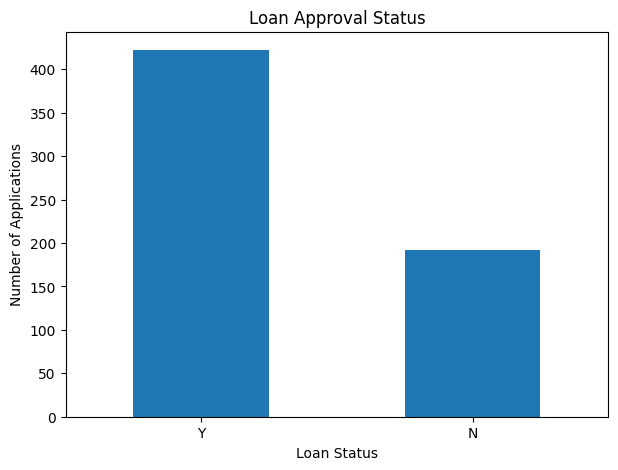

In [ ]:
#This cell creates a bar chart showing approved and rejected loans.
# Create loan approval bar chart

df['Loan_Status'].value_counts().plot(
    kind='bar',
    figsize=(7, 5)
)

plt.title("Loan Approval Status")
plt.xlabel("Loan Status")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)

plt.show()

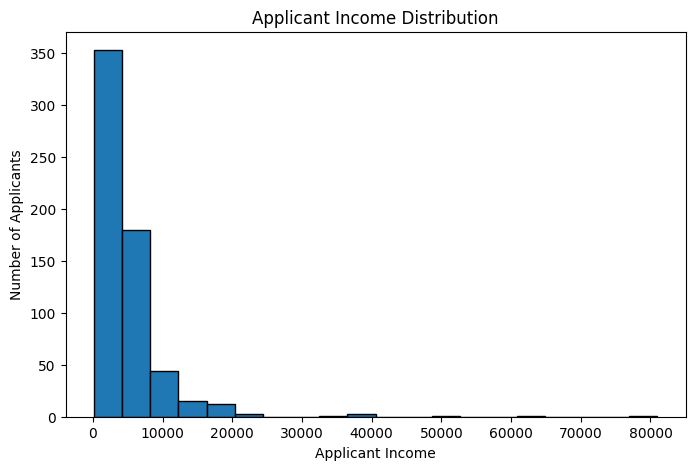

In [ ]:
#This cell shows the distribution of applicant income.
# Display applicant income distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df['ApplicantIncome'],
    bins=20,
    edgecolor='black'
)

plt.title("Applicant Income Distribution")
plt.xlabel("Applicant Income")
plt.ylabel("Number of Applicants")

plt.show()

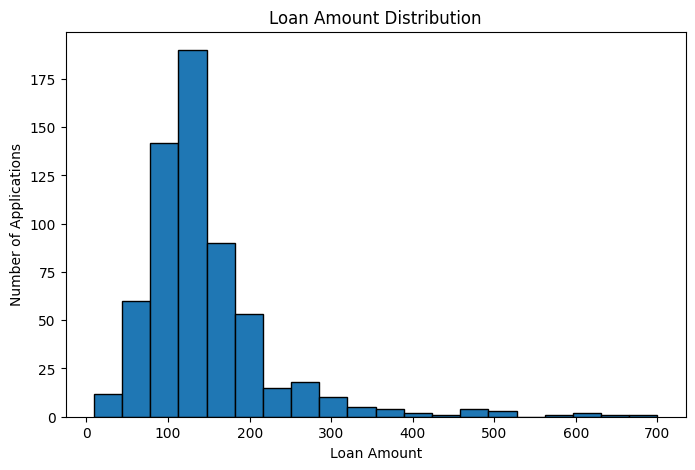

In [ ]:
#This cell shows how loan amounts are distributed among applicants.
# Display loan amount distribution

plt.figure(figsize=(8, 5))

plt.hist(
    df['LoanAmount'],
    bins=20,
    edgecolor='black'
)

plt.title("Loan Amount Distribution")
plt.xlabel("Loan Amount")
plt.ylabel("Number of Applications")

plt.show()

Credit History vs Loan Status:


Loan_Status,N,Y
Credit_History,,
0.0,82,7
1.0,110,415


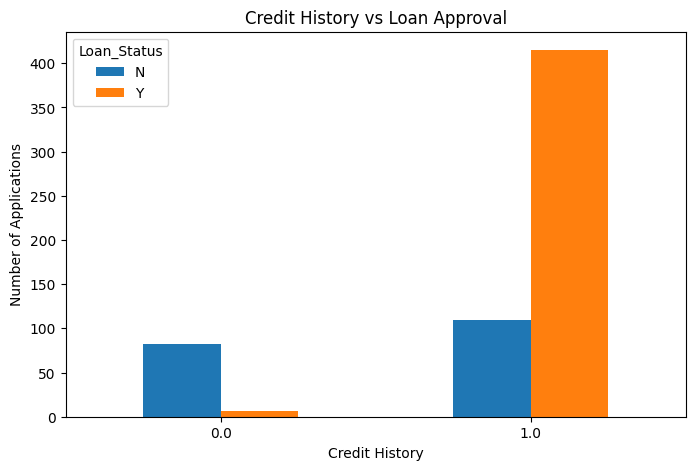

In [ ]:
#This cell compares credit history with loan approval status.
# Compare credit history with loan approval

credit_analysis = pd.crosstab(
    df['Credit_History'],
    df['Loan_Status']
)

print("Credit History vs Loan Status:")
display(credit_analysis)

credit_analysis.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Credit History vs Loan Approval")
plt.xlabel("Credit History")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)

plt.show()

Loan_Status,N,Y
Education,,
Graduate,140,340
Not Graduate,52,82


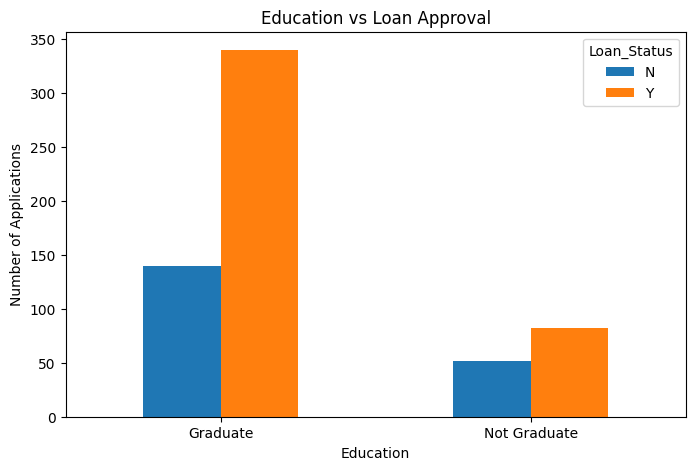

In [ ]:
#This cell compares the education level of applicants with their loan status.
# Compare education with loan approval

education_analysis = pd.crosstab(
    df['Education'],
    df['Loan_Status']
)

display(education_analysis)

education_analysis.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Education vs Loan Approval")
plt.xlabel("Education")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)

plt.show()

Loan_Status,N,Y
Property_Area,,
Rural,69,110
Semiurban,54,179
Urban,69,133


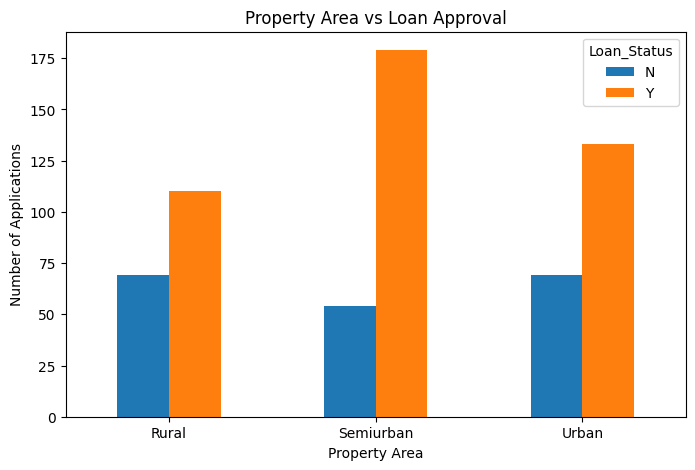

In [ ]:
#This cell compares property area with loan approval status.
# Compare property area with loan approval

property_analysis = pd.crosstab(
    df['Property_Area'],
    df['Loan_Status']
)

display(property_analysis)

property_analysis.plot(
    kind='bar',
    figsize=(8, 5)
)

plt.title("Property Area vs Loan Approval")
plt.xlabel("Property Area")
plt.ylabel("Number of Applications")
plt.xticks(rotation=0)

plt.show()

In [ ]:
# This cell calculates average income and loan amount for approved and rejected applications.
# Compare average values by loan status

analysis = df.groupby('Loan_Status')[
    ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount']
].mean()

display(analysis)

,ApplicantIncome,CoapplicantIncome,LoanAmount
Loan_Status,,,
N,5446.078125,1877.807292,149.890625
Y,5384.068720,1504.516398,143.869668


In [ ]:
# This cell converts categorical values into numerical values for further analysis.
# Convert categorical columns into numerical columns

encoded_df = pd.get_dummies(
    df,
    columns=[
        'Gender',
        'Married',
        'Dependents',
        'Education',
        'Self_Employed',
        'Property_Area'
    ],
    drop_first=True
)

print("Categorical data encoded successfully!")

display(encoded_df.head())

Categorical data encoded successfully!


,Loan_ID,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Loan_Status,Gender_Male,Married_Yes,Dependents_1,Dependents_2,Dependents_3+,Education_Not Graduate,Self_Employed_Yes,Property_Area_Semiurban,Property_Area_Urban
0,LP001002,5849,0.0,128.0,360.0,1.0,Y,True,False,False,False,False,False,False,False,True
1,LP001003,4583,1508.0,128.0,360.0,1.0,N,True,True,True,False,False,False,False,False,False
2,LP001005,3000,0.0,66.0,360.0,1.0,Y,True,True,False,False,False,False,True,False,True
3,LP001006,2583,2358.0,120.0,360.0,1.0,Y,True,True,False,False,False,True,False,False,True
4,LP001008,6000,0.0,141.0,360.0,1.0,Y,True,False,False,False,False,False,False,False,True


In [ ]:
########
# This cell applies Min-Max scaling to the numerical columns (values become 0 to 1).
num_cols = ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term']

scaled_df = encoded_df.copy()

for col in num_cols:
    scaled_df[col] = (scaled_df[col] - scaled_df[col].min()) / (scaled_df[col].max() - scaled_df[col].min())

print("Min-Max scaling applied successfully!")
display(scaled_df[num_cols].describe().loc[['min', 'max']])
display(scaled_df[num_cols].head())

Min-Max scaling applied successfully!


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
min,0.0,0.0,0.0,0.0
max,1.0,1.0,1.0,1.0


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.070489,0.000000,0.172214,0.74359
1,0.054830,0.036192,0.172214,0.74359
2,0.035250,0.000000,0.082489,0.74359
3,0.030093,0.056592,0.160637,0.74359
4,0.072356,0.000000,0.191027,0.74359


In [ ]:
# This cell applies standardization (z-score) so each column has mean 0 and std 1.
standardized_df = encoded_df.copy()

for col in num_cols:
    standardized_df[col] = (standardized_df[col] - standardized_df[col].mean()) / standardized_df[col].std()

print("Standardization applied successfully!")
display(standardized_df[num_cols].describe().loc[['mean', 'std']].round(2))
display(standardized_df[num_cols].head())

Standardization applied successfully!


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
mean,-0.0,0.0,-0.0,0.0
std,1.0,1.0,1.0,1.0


,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term
0,0.072931,-0.554036,-0.211069,0.273009
1,-0.134302,-0.038700,-0.211069,0.273009
2,-0.393427,-0.554036,-0.948223,0.273009
3,-0.461686,0.251774,-0.306186,0.273009
4,0.097649,-0.554036,-0.056505,0.273009


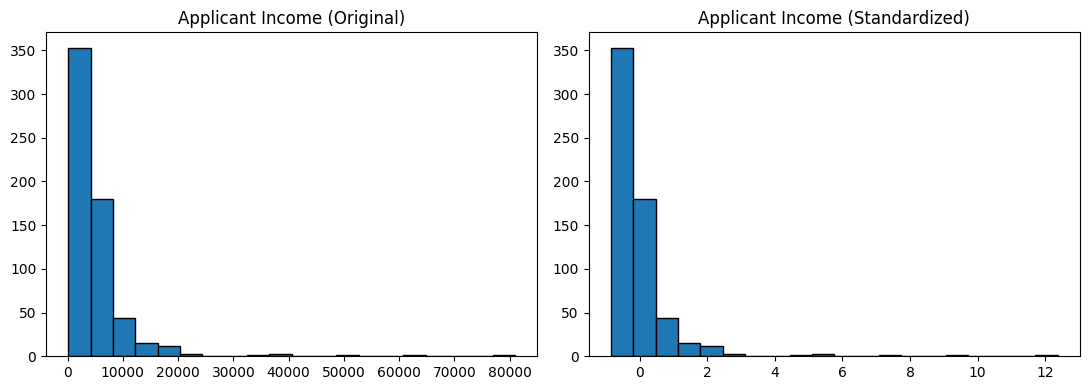

In [ ]:
# This cell compares the original and standardized income values.
fig, axes = plt.subplots(1, 2, figsize=(11, 4))

axes[0].hist(encoded_df['ApplicantIncome'], bins=20, edgecolor='black')
axes[0].set_title("Applicant Income (Original)")

axes[1].hist(standardized_df['ApplicantIncome'], bins=20, edgecolor='black')
axes[1].set_title("Applicant Income (Standardized)")

plt.tight_layout()
plt.show()

#####

In [ ]:
#This cell checks the relationship between numerical variables.
# Calculate correlation between numerical variables

correlation = encoded_df.select_dtypes(
    include=np.number
).corr()

display(correlation)

,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History
ApplicantIncome,1.000000,-0.116605,0.565181,-0.046531,-0.018615
CoapplicantIncome,-0.116605,1.000000,0.189218,-0.059383,0.011134
LoanAmount,0.565181,0.189218,1.000000,0.036960,-0.000607
Loan_Amount_Term,-0.046531,-0.059383,0.036960,1.000000,-0.004705
Credit_History,-0.018615,0.011134,-0.000607,-0.004705,1.000000


In [ ]:
#This cell demonstrates a basic rule-based method for estimating loan approval.
# Create a simple rule-based loan approval function

def loan_approval_check(credit_history, applicant_income, loan_amount):

    if credit_history == 1 and applicant_income >= loan_amount * 10:
        return "Likely Approved"

    elif credit_history == 1 and applicant_income >= loan_amount * 5:
        return "Review Required"

    else:
        return "Likely Rejected"


# Test the function with a sample applicant

result = loan_approval_check(
    credit_history=1,
    applicant_income=5000,
    loan_amount=300
)

print("Estimated Loan Status:", result)

Estimated Loan Status: Likely Approved


In [ ]:
#This cell displays the main results of the loan approval analysis.
# Display final project summary

print("======================================")
print("     LOAN APPROVAL ANALYSIS")
print("======================================")

print("Total Applications:", len(df))

print(
    "Approved Applications:",
    (df['Loan_Status'] == 'Y').sum()
)

print(
    "Rejected Applications:",
    (df['Loan_Status'] == 'N').sum()
)

print(
    "Average Applicant Income:",
    round(df['ApplicantIncome'].mean(), 2)
)

print(
    "Average Loan Amount:",
    round(df['LoanAmount'].mean(), 2)
)

print(
    "Missing Values:",
    df.isnull().sum().sum()
)

print(
    "Duplicate Records:",
    df.duplicated().sum()
)

print("======================================")
print("Analysis completed successfully!")

     LOAN APPROVAL ANALYSIS
Total Applications: 614
Approved Applications: 422
Rejected Applications: 192
Average Applicant Income: 5403.46
Average Loan Amount: 145.75
Missing Values: 0
Duplicate Records: 0
Analysis completed successfully!
